# ESP streamflow ensemble evaluation

Score Ensemble Streamflow Prediction (ESP) traces against gauge observations.

- **CRPS / CRPSS** vs observational climatology (same calendar day, other years)
- **Peak-flow CRPS / CRPSS** (optional): one score per forecast for the maximum discharge over the horizon, versus observed peaks in that same calendar window
- **Peak-over-horizon** Brier score and Brier skill score at the `Yp` thresholds, plus a reliability diagram and an ROC curve for the same ensemble exceedance probabilities
- Results are aggregated by forecast-initiation month (`02-01`, `03-01`, …)

This notebook calls library functions; it is not the source of truth. CLI equivalent:
`python -m snowda.workflows.evaluate_esp_streamflow ../runs/examples/ross_evaluate_esp.yaml`

In [12]:
from pathlib import Path

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Decision points

These arguments control the evaluation. Defaults match the plan: fair CRPS, leave-one-out climatology, peak-over-horizon events, and a 0.5 probability threshold for POD/FAR. Set `SCORE_PEAK` to score the maximum discharge over each forecast horizon.

In [13]:
from pathlib import Path

RUN_DIR = Path("/Users/dcasson/GitHub/snowda/outputs/ross_summa_esp/complete_run")
OBS_CSV = Path("/Users/dcasson/Data/snowda/summa/ross_lumped/observations/streamflow.csv")
THRESHOLDS_CSV = Path("/Users/dcasson/Data/snowda/summa/ross_lumped/thresholds/ross_thresholds.csv")
OUTPUT_DIR = Path("/Users/dcasson/GitHub/snowda/outputs/ross_esp_streamflow_eval")

RETURN_PERIODS = (2, 5, 10, 20)
EVENT_PROBABILITY_THRESHOLD = 0.5
EXCLUDE_VERIFICATION_YEAR = True
CRPS_METHOD = "fair"  # "fair" or "ecdf"
FAIR_BRIER = True
SCORE_PEAK = True  # one peak-flow CRPS and CRPSS per forecast
RESAMPLE = "1D"
VARIABLE = "IRFroutedRunoff"
SEG = 0

## Load traces and score

In [14]:
import pandas as pd

from snowda.io.esp_streamflow import load_esp_forecasts, read_return_period_thresholds
from snowda.workflows.evaluate_esp_streamflow import (
    compute_esp_metrics,
    esp_metrics_to_dict,
    write_esp_evaluation_products,
)

forecasts, obs = load_esp_forecasts(
    RUN_DIR,
    OBS_CSV,
    variable=VARIABLE,
    resample=RESAMPLE,
    seg=SEG,
)
thresholds = read_return_period_thresholds(THRESHOLDS_CSV)
metrics = compute_esp_metrics(
    forecasts,
    obs,
    thresholds,
    return_periods=RETURN_PERIODS,
    event_probability_threshold=EVENT_PROBABILITY_THRESHOLD,
    exclude_verification_year=EXCLUDE_VERIFICATION_YEAR,
    crps_method=CRPS_METHOD,
    fair_brier=FAIR_BRIER,
    score_peak=SCORE_PEAK,
)
payload = esp_metrics_to_dict(metrics)
print(f"Forecasts: {len(forecasts)}; init months: {payload['init_months']}")
metrics

Forecasts: 114; init months: ['03-01', '04-01', '05-01']


<xarray.Dataset> Size: 39kB
Dimensions:            (init_month: 3, lead: 153, rank: 40, init_time: 114,
                        return_period: 4)
Coordinates:
  * lead               (lead) int64 1kB 0 1 2 3 4 5 ... 147 148 149 150 151 152
  * rank               (rank) int64 320B 1 2 3 4 5 6 7 ... 34 35 36 37 38 39 40
  * init_time          (init_time) datetime64[ns] 912B 1981-03-01 ... 2018-05-01
  * return_period      (return_period) int64 32B 2 5 10 20
  * init_month         (init_month) object 24B '03-01' '04-01' '05-01'
Data variables: (12/21)
    crps               (init_month, lead) float64 4kB 3.583 3.599 ... nan nan
    crpss              (init_month, lead) float64 4kB -3.533 -3.549 ... nan nan
    crps_mean          (init_month) float64 24B 25.84 31.12 38.11
    crpss_mean         (init_month) float64 24B -1.613 -0.9394 -0.06326
    rank_histogram     (init_month, rank) float64 960B 0.04678 ... 0.1044
    rank_histogram_n   (init_month) int64 24B 5814 4636 3496
    ...                 ...
    yp                 (init_month, return_period) float64 96B 387.1 ... 646.1
    event_probability  (init_month, return_period, init_time) float64 11kB 0....
    event_observed     (init_month, return_period, init_time) float64 11kB 0....
    n_forecasts        (init_month) int64 24B 38 38 38
    n_pairs            (init_month) int64 24B 5814 4636 3496
    n_members          (init_month) int64 24B 39 39 39
Attributes: (12/13)
    n_forecasts:                  114
    n_pairs:                      13946
    scores_version:               2.7.0
    crps_method:                  fair
    fair_brier:                   True
    event_probability_threshold:  0.5
    ...                           ...
    return_periods:               2,5,10,20
    skill_reference:              observational streamflow climatology
    binary_event:                 peak-over-horizon
    score_peak:                   True
    peak_definition:              maximum streamflow over the forecast horizon
    peak_skill_reference:         observational peak streamflow in the same c...

In [15]:
rows = []
for month, row in payload["by_init_month"].items():
    entry = {
        "init_month": month,
        "n_forecasts": row["n_forecasts"],
        "n_members": row["n_members"],
        "n_pairs": row["n_pairs"],
        "crps_mean": row["crps_mean"],
        "crpss_mean": row["crpss_mean"],
    }
    if "peak_crps_mean" in row:
        entry["peak_crps_mean"] = row["peak_crps_mean"]
        entry["peak_crpss_mean"] = row["peak_crpss_mean"]
    for period in payload["return_periods"]:
        key = str(period)
        entry[f"bs_{key}"] = row["bs"][key]
        entry[f"bss_{key}"] = row["bss"][key]
        entry[f"pod_{key}"] = row["pod"][key]
        entry[f"far_{key}"] = row["far"][key]
    rows.append(entry)

summary = pd.DataFrame(rows).set_index("init_month")

peak_rows = []
for month, row in payload["by_init_month"].items():
    for init, crps in row.get("peak_crps", {}).items():
        peak_rows.append(
            {
                "init_time": init,
                "init_month": month,
                "peak_crps": crps,
                "peak_crpss": row["peak_crpss"][init],
            }
        )
if peak_rows:
    from IPython.display import display

    display(pd.DataFrame(peak_rows).set_index("init_time"))
summary

,init_month,peak_crps,peak_crpss
init_time,,,
1981-03-01 00:00:00,03-01,37.785324,0.066964
1982-03-01 00:00:00,03-01,14.937539,0.731310
1983-03-01 00:00:00,03-01,156.617921,-0.227782
1984-03-01 00:00:00,03-01,11.998894,0.661361
1985-03-01 00:00:00,03-01,15.965127,0.720923
...,...,...,...
2014-05-01 00:00:00,05-01,14.840141,0.560442
2015-05-01 00:00:00,05-01,6.271894,0.830748
2016-05-01 00:00:00,05-01,7.252583,0.785494


,n_forecasts,n_members,n_pairs,crps_mean,crpss_mean,peak_crps_mean,peak_crpss_mean,bs_2,bss_2,pod_2,...,pod_5,far_5,bs_10,bss_10,pod_10,far_10,bs_20,bss_20,pod_20,far_20
init_month,,,,,,,,,,,,,,,,,,,,,
03-01,38,39,5814,25.837915,-1.613231,53.139698,0.232041,0.164074,0.368821,0.882353,...,0.4,0.333333,0.079267,-0.043030,0.0,1.0,0.052276,-0.013945,0.0,NaN
04-01,38,39,4636,31.122611,-0.939398,53.446446,0.246519,0.158214,0.391363,0.823529,...,0.4,0.500000,0.083671,-0.100976,0.0,1.0,0.053626,-0.040120,0.0,NaN
05-01,38,39,3496,38.112845,-0.063256,50.666603,0.286748,0.184992,0.292040,0.764706,...,0.2,0.000000,0.096207,-0.263433,0.0,1.0,0.053910,-0.044674,0.0,NaN


## Visualize

Hydrograph envelopes use the paired ESP traces. Metric plots use the aggregated `metrics` dataset. The peak-score plot shows one CRPS and one CRPSS per initialization time.

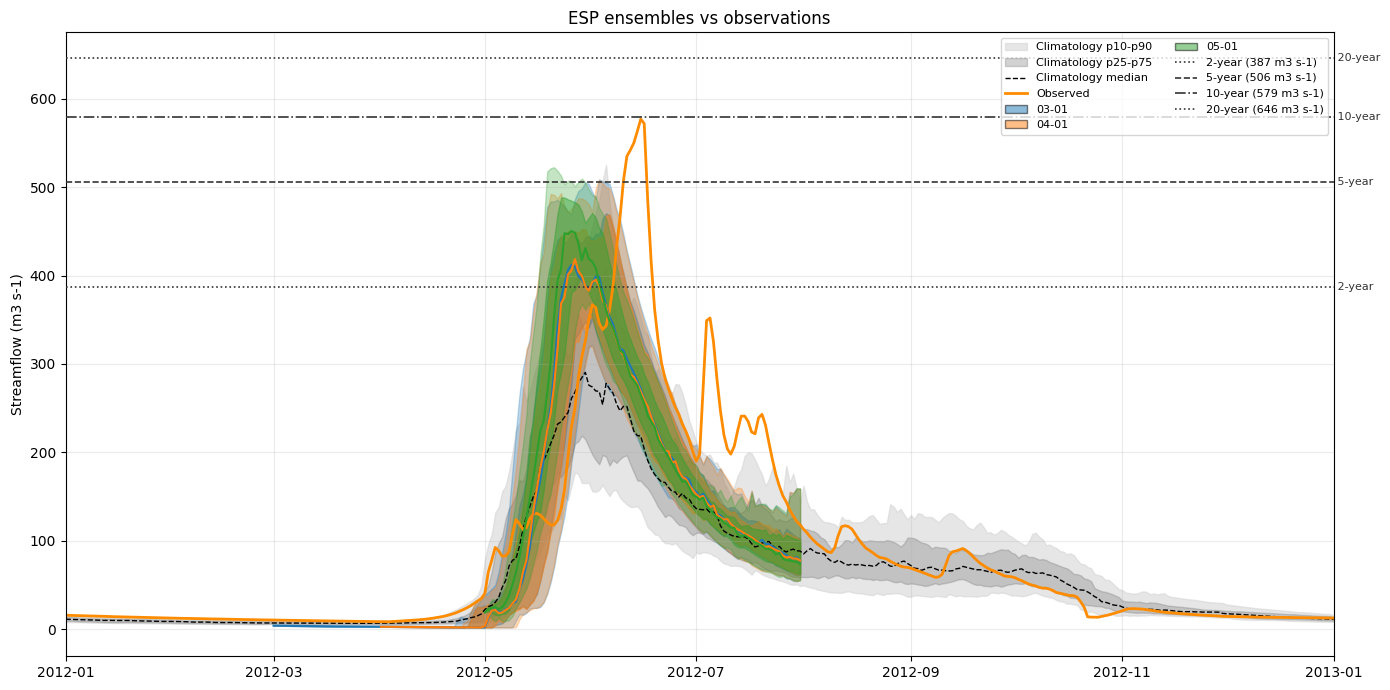

In [16]:
from snowda.io.esp_streamflow import select_return_period_thresholds
from snowda.viz.esp_streamflow import (
    plot_crps_by_lead,
    plot_ensemble_envelopes,
    plot_ensemble_forecast_separate,
    plot_peak_scores,
    plot_threshold_metrics,
)

plot_thresholds = select_return_period_thresholds(thresholds, RETURN_PERIODS)
PLOT_START = "2012-01-01"
PLOT_END = "2013-01-01"
fig, ax = plot_ensemble_envelopes(
    forecasts,
    obs,
    title="ESP ensembles vs observations",
    thresholds=plot_thresholds,
    start=PLOT_START,
    end=PLOT_END,
)

In [17]:
from IPython.display import display

#for forecast in forecasts:
#    fig, ax = plot_ensemble_forecast_separate(
#        forecast, obs, thresholds=plot_thresholds
#    )

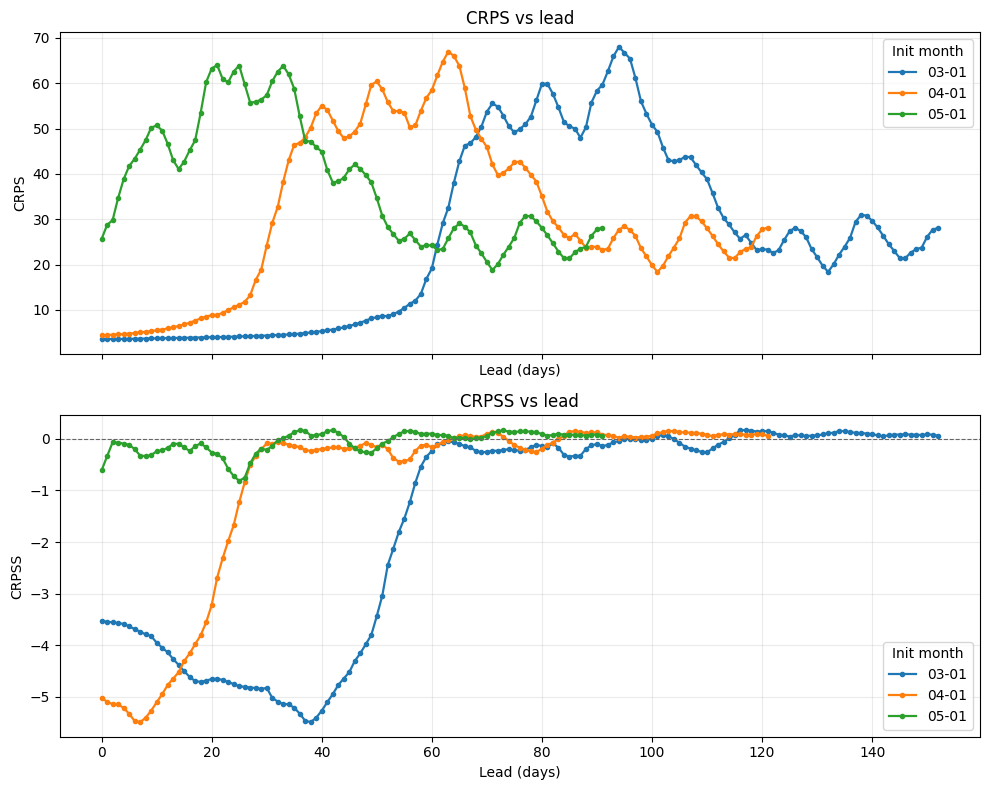

In [18]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
plot_crps_by_lead(metrics, ax=axes[0], skill=False)
plot_crps_by_lead(metrics, ax=axes[1], skill=True)
fig.tight_layout()

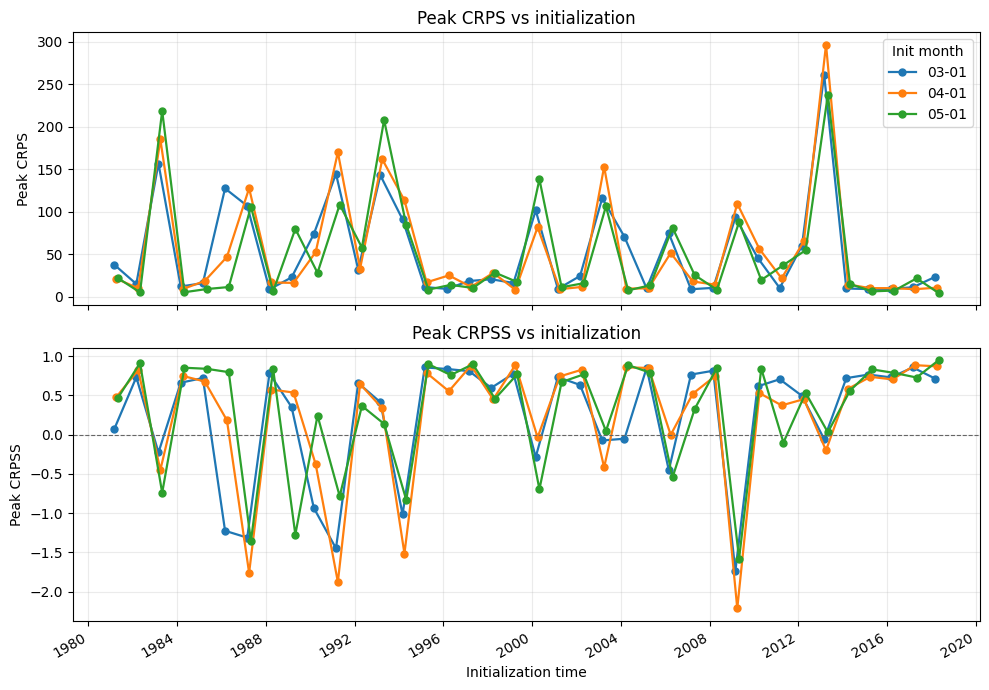

In [19]:
fig = plot_peak_scores(metrics)

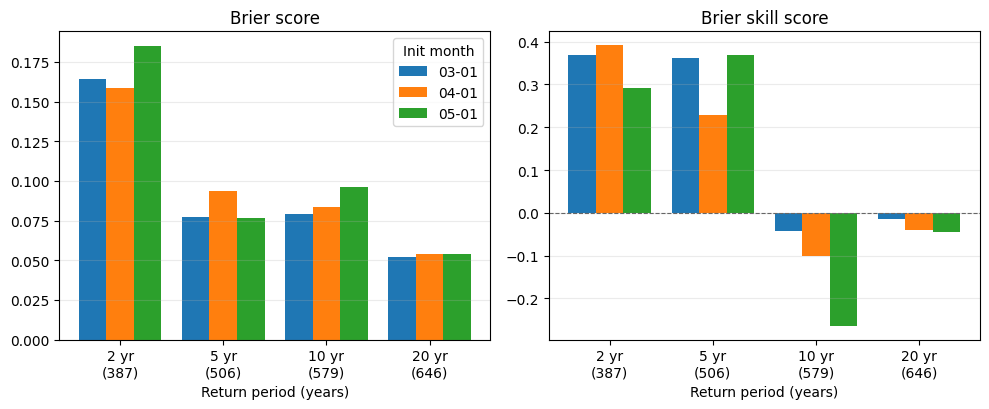

In [20]:
fig = plot_threshold_metrics(metrics)

## Reliability and ROC

Both diagrams use the peak-over-horizon ensemble probability: the fraction of members whose peak flow exceeds `Yp`, compared with whether the observed peak exceeds that same threshold. One panel per return period and one curve per initiation month. Empty reliability bins are omitted, and marker area shows how many forecasts fell in the bin.

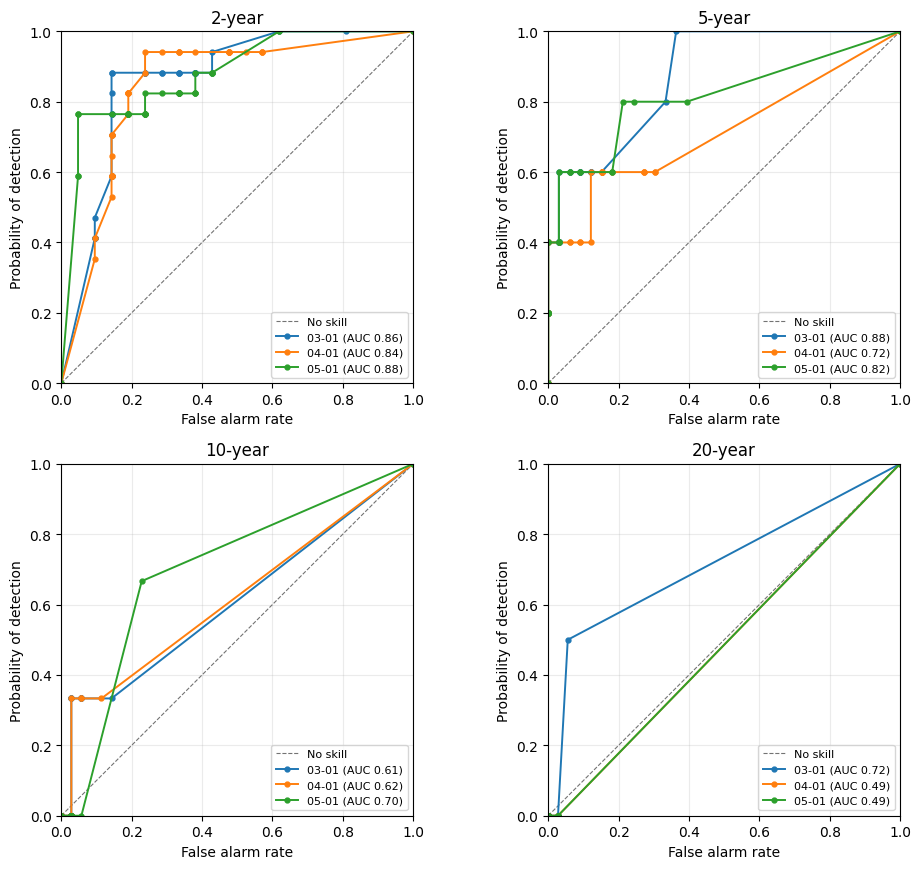

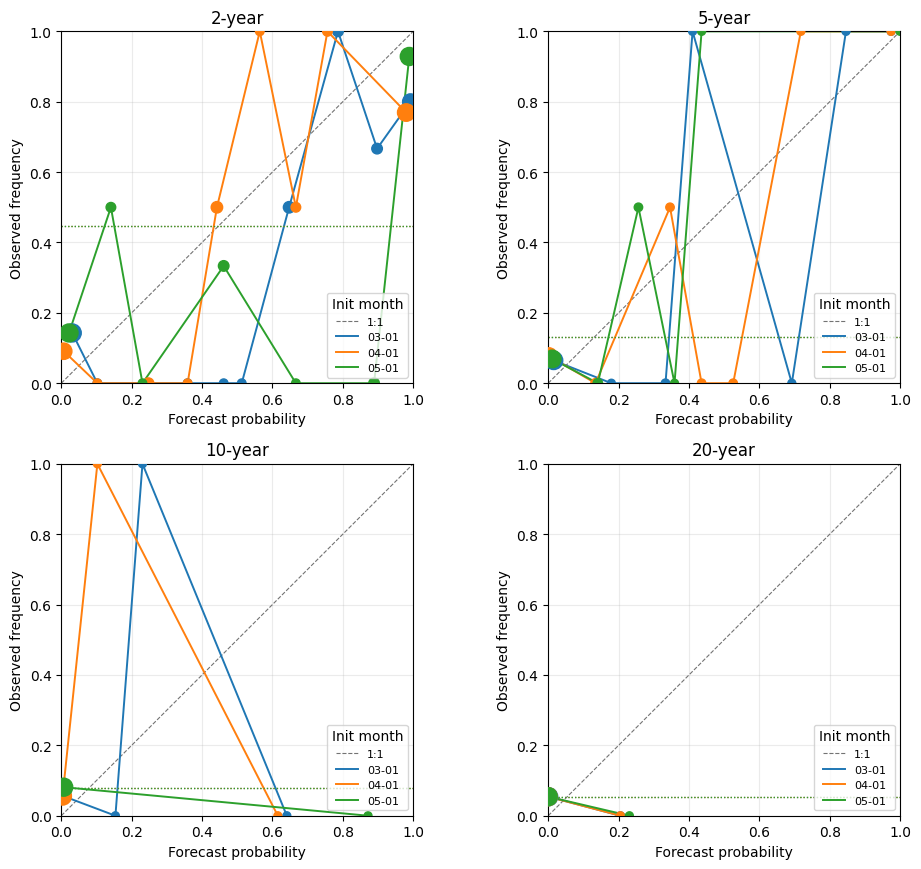

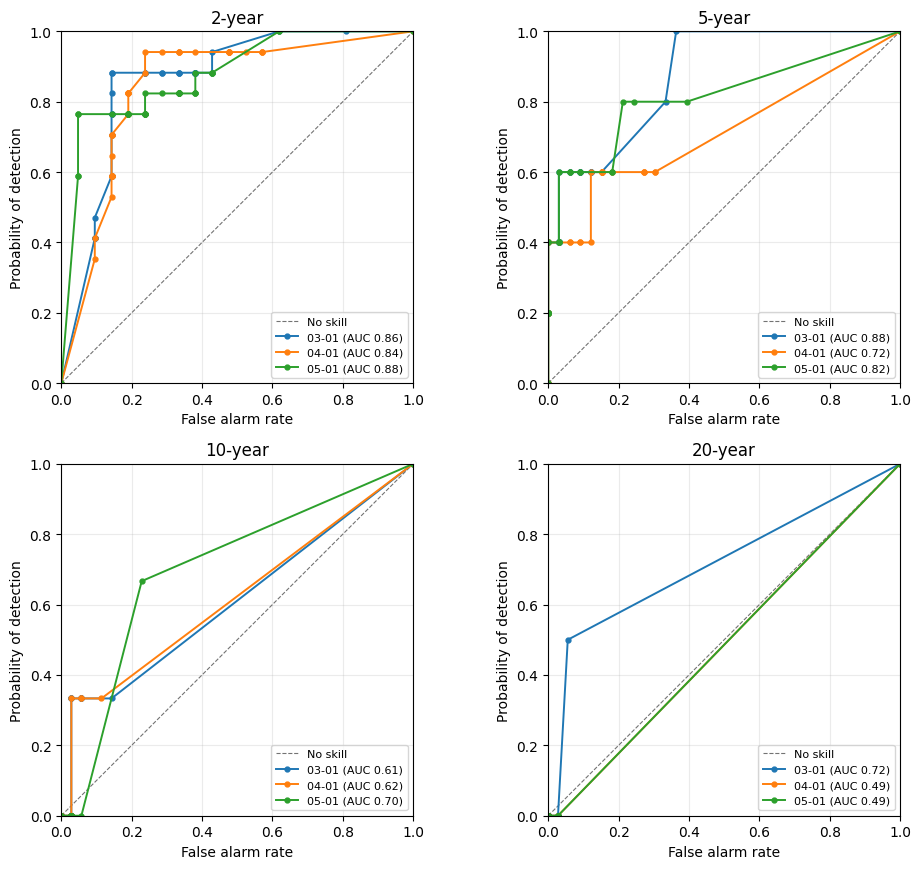

In [21]:
from snowda.adapters.scores import reliability_diagram, roc_diagram
from snowda.viz.esp_streamflow import plot_reliability_diagram, plot_roc_diagram

reliability = reliability_diagram(
    metrics["event_probability"],
    metrics["event_observed"],
)
roc = roc_diagram(
    metrics["event_probability"],
    metrics["event_observed"],
)
plot_reliability_diagram(reliability)
plot_roc_diagram(roc)

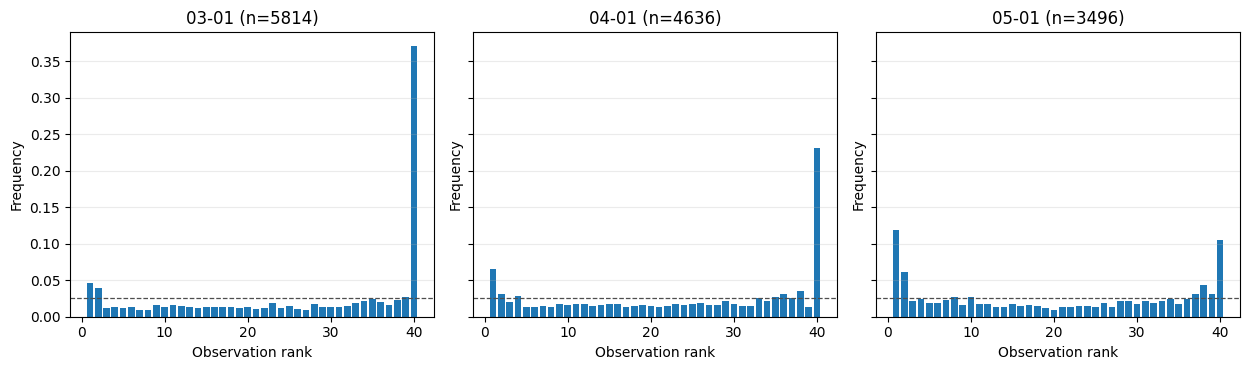

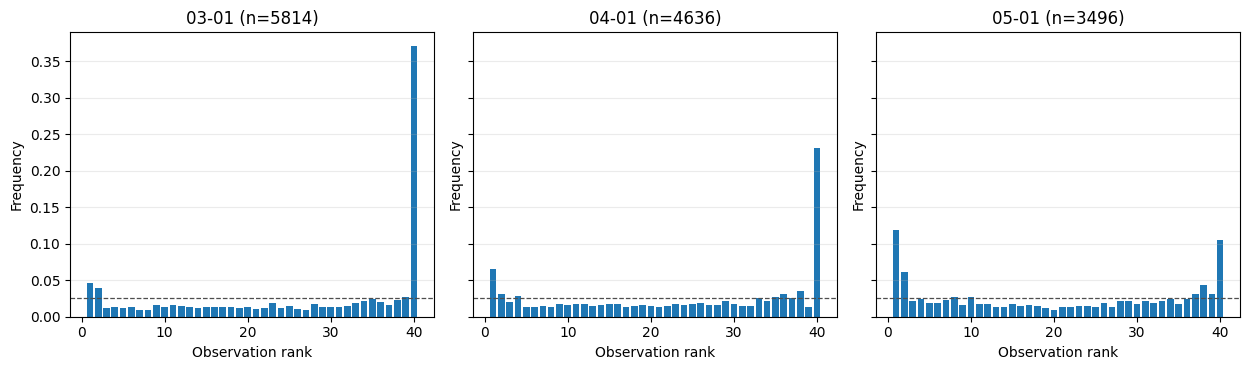

In [23]:
from snowda.viz.esp_streamflow import plot_rank_histogram

plot_rank_histogram(metrics)

## Write artifacts (optional)

Writes `metrics.nc` and `metrics.json` into a timestamped folder under `OUTPUT_DIR`.

In [22]:
from datetime import datetime, timezone

eval_dir = OUTPUT_DIR / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
write_esp_evaluation_products(metrics, eval_dir)
print("Wrote evaluation to", eval_dir)

Wrote evaluation to /Users/dcasson/GitHub/snowda/outputs/ross_esp_streamflow_eval/20261001T172504Z
